In [1]:
import os, importlib, sys, time

In [2]:
import numpy as np
import scipy.sparse as sparse
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
from tqdm import tqdm

In [3]:
import KECENI

# load data

In [4]:
data_dir = 'data'

In [5]:
i_sim = 0

In [6]:
data_network = pd.read_feather('%s/network.feather'%(data_dir))
data_latent = pd.read_feather('%s/latent.feather'%data_dir)
data_feature = pd.read_feather('%s/feature_%.3d.feather'%(data_dir, i_sim))

In [7]:
data_network

,row,col
0,1,2
1,1,5
2,1,7
3,1,14
4,2,1
...,...,...
3737,999,897
3738,1000,785
3739,1000,891
3740,1000,949


In [8]:
data_feature

,X1,X2,X3,p,T,m,Y
0,-0.794586,-1.292653,1.887724,0.475081,1,0.439838,-0.179627
1,-2.212908,-0.683285,-1.054355,0.121824,0,3.793276,4.716915
2,0.392061,-1.099816,0.484387,0.472108,1,2.016744,0.478023
3,-0.555751,0.057301,-0.744850,0.349406,0,1.630082,0.692316
4,1.245434,1.377084,1.521976,0.888176,1,-4.465799,-4.713689
...,...,...,...,...,...,...,...
995,-0.576297,-0.085715,-0.164399,0.398144,0,-0.122879,-0.138864
996,0.875659,-0.165591,0.068915,0.596160,0,-2.353876,-2.764397
997,-0.638549,1.540622,0.026466,0.614027,1,-0.013294,0.304892
998,0.135169,-0.959663,0.449760,0.453295,1,4.203064,1.900993


In [9]:
n_node = len(data_latent); n_node

1000

In [10]:
len(data_network)

3742

In [11]:
Adj = sparse.csr_matrix((
    np.full(len(data_network), True), 
    (np.array(data_network.row)-1, np.array(data_network.col)-1)
)).toarray()

In [12]:
G = KECENI.Graph(Adj)

In [13]:
Ys = data_feature.iloc[:,6].values
Ts = data_feature.iloc[:,4].values
Xs = data_feature.iloc[:,0:3].values

In [14]:
data = KECENI.Data(Ys, Ts, Xs, G)

# hyperparameters

In [15]:
from hyperparams import delta, HyperAlpha

# counterfactual of interest

In [16]:
i0 = 0

In [17]:
T0s_1 = np.zeros(n_node); T0s_1[G.N1(i0)[::2]] = 1
T0s_0 = T0s_1.copy(); T0s_0[i0] = 0

In [18]:
T0s_0[G.N1(i0)], T0s_1[G.N1(i0)]

(array([0., 0., 1., 0., 1.]), array([1., 0., 1., 0., 1.]))

In [19]:
i0s = np.array([i0])
T0s = np.array([T0s_0, T0s_1])

# groundtruth

In [20]:
from KECENI.RegressionModel import FittedRegressionModel
from KECENI.PropensityModel import FittedPropensityModel
from KECENI.CovariateModel import FittedCovariateModel

In [21]:
from true_model import mu, pi, rX

In [22]:
true_model = KECENI.Model(
    FittedRegressionModel(mu),
    FittedPropensityModel(pi),
    FittedCovariateModel(rX),
    delta
)

In [23]:
true_fit = true_model.fit(data)

In [24]:
result_true = true_fit.G_estimate(i0s, T0s, n_X=10000)

In [25]:
YTR_0, YTR_1 = result_true.reshape([2, -1])
YTR_d = YTR_1 - YTR_0

In [26]:
YTR_0, YTR_1, YTR_d

(array([-0.96165333]), array([0.99739575]), array([1.95904907]))

# estimation

In [27]:
from KECENI.RegressionModel import LinearRegressionModel
from KECENI.PropensityModel import LogisticIIDPropensityModel
from KECENI.CovariateModel import IIDCovariateModel

In [28]:
hyper = HyperAlpha(0, 0)

In [29]:
keceni_model = KECENI.Model(
    LinearRegressionModel(hyper.summary_mu),
    LogisticIIDPropensityModel(hyper.summary_pi),
    IIDCovariateModel(),
    delta
)

In [30]:
keceni_fit = keceni_model.fit(data, tqdm=tqdm)

/depot/bong0/etc/envs/causalnet-negishi/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
fit: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:02<00:00, 439.92it/s]


## - cross-validation

In [31]:
lamdas = np.linspace(0, 20, 21)[1:]

In [32]:
result_cv = keceni_fit.cv(
    tqdm=tqdm
)

cv: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:25<00:00, 38.50it/s]


In [33]:
xs_cv, xhs_cv = result_cv.xs_xhs(lamdas)

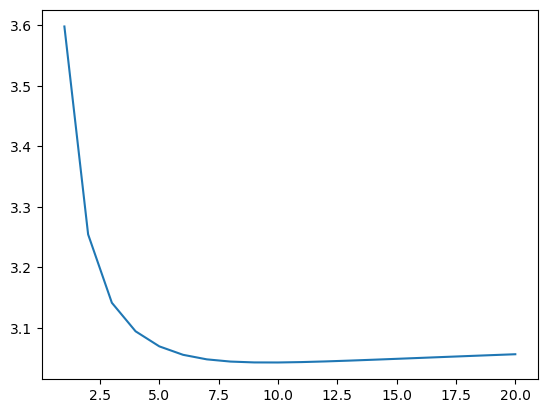

In [34]:
plt.plot(lamdas, np.mean((xs_cv-xhs_cv)**2, -1))

In [35]:
id_cv = np.argmin(np.mean((xs_cv-xhs_cv)**2, -1))
id_cv

9

In [36]:
# id_cv = (9,)

In [37]:
lamdas[id_cv]

10.0

## - G estimate

In [38]:
result_G = keceni_fit.G_estimate(i0s, T0s, n_X=1000)

In [39]:
YG_0, YG_1 = np.moveaxis(result_G, -1, 0)
YG_d = YG_1 - YG_0

In [40]:
YG_0, YG_1, YG_d

(-0.9730742933553315, 0.9150995487401852, 1.8881738420955165)

## - KECENI

In [41]:
result_AIPW = keceni_fit.kernel_AIPW(
    i0s, T0s, tqdm=tqdm
)

AIPW: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:01<00:00, 624.53it/s]


In [42]:
YDR_0, YDR_1 = result_AIPW.est(lamdas[id_cv])
YDR_d = YDR_1 - YDR_0

In [43]:
YDR_0, YDR_1, YDR_d

(-0.9732127259036665, 1.129997653242006, 2.1032103791456724)

# inference

In [44]:
import KECENI.Inference as inf

## - $\phi$ and $H$

In [45]:
# cov_bst = keceni_fit.cov_bst(n_bst=120)

In [46]:
phis_eif = result_AIPW.phis_eif(lamdas)

In [47]:
wH_nu = result_AIPW.wH_nu(lamdas, n_X=1000, tqdm=tqdm)

Hs_nu: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:31<00:00, 31.77it/s]


In [48]:
wH_px = result_AIPW.wH_px(lamdas, n_X=5000, tqdm=tqdm)

Hs_px: 100%|█████████████████████████████████| 1000/1000 [00:15<00:00, 64.48it/s]


In [49]:
# wH_nu = result_AIPW.Hs_nu(lamdas, n_X=100, tqdm=tqdm)

In [50]:
# wH_px = result_AIPW.Hs_px(lamdas, n_sample=10, tqdm=tqdm)

## - distance in $\mathcal{G}$

In [51]:
G.get_dist()

array([[ 0.,  1.,  2., ..., 15., 15., 17.],
       [ 1.,  0.,  1., ..., 15., 16., 16.],
       [ 2.,  1.,  0., ..., 16., 17., 16.],
       ...,
       [15., 15., 16., ...,  0., 28., 21.],
       [15., 16., 17., ..., 28.,  0., 26.],
       [17., 16., 16., ..., 21., 26.,  0.]])

In [52]:
G_sub = G.sub(keceni_fit.js)

In [53]:
G_sub.dist = G.dist[np.ix_(keceni_fit.js, keceni_fit.js)]

## - sandwich variance HAC estimator

In [54]:
phis_dr = phis_eif + wH_nu[keceni_fit.js] + wH_px[keceni_fit.js]

In [59]:
inf.ste_hac_sdw(phis_dr, G_sub, inf.box_kernel, bw=[1])[:,id_cv]

array([[0.17957821, 0.18581129]])

In [60]:
inf.ste_hac_sdw(phis_dr[...,1]-phis_dr[...,0], G_sub, inf.box_kernel, bw=[1])[:,id_cv]

array([0.14254064])